# LeNet Architecture

In [1]:
# Import the warnings
import warnings
warnings.filterwarnings("ignore")

In [2]:
# Import the neccesary Packages.
import os
import glob
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import Activation
from tensorflow.keras.callbacks import ModelCheckpoint
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D
from tensorflow.keras.layers import Convolution2D
from tensorflow.keras.layers import Dropout
from tensorflow.keras.layers import MaxPool2D
from tensorflow.keras.layers import MaxPooling2D
from tensorflow.keras.layers import Flatten
from tensorflow.keras.layers import Dense

In [3]:
train_datagen=ImageDataGenerator(rescale=1./255,shear_range=0.2,zoom_range=0.2,horizontal_flip=True)
training_set=train_datagen.flow_from_directory('datasets/train',target_size=(224,224),batch_size=32,class_mode='categorical')

Found 1400 images belonging to 2 classes.


In [4]:
test_datagen=ImageDataGenerator(rescale=1./255)
test_set=test_datagen.flow_from_directory('datasets/test',target_size=(224,224),batch_size=32,class_mode='categorical')

Found 600 images belonging to 2 classes.


In [5]:
Classifier=Sequential()
Classifier.add(Convolution2D(32,3,3,input_shape=(224,224,3),activation='relu'))
Classifier.add(MaxPooling2D(pool_size=(2,2)))
Classifier.add(Convolution2D(128,3,3,activation='relu'))
Classifier.add(MaxPooling2D(pool_size=(2,2)))
Classifier.add(Flatten())
Classifier.add(Dense(256, activation='relu'))
Classifier.add(Dense(2, activation='softmax'))

Classifier.compile(optimizer='rmsprop',loss='categorical_crossentropy',metrics=['accuracy'])
Classifier.summary()




Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 74, 74, 32)        896       
                                                                 
 max_pooling2d (MaxPooling2  (None, 37, 37, 32)        0         
 D)                                                              
                                                                 
 conv2d_1 (Conv2D)           (None, 12, 12, 128)       36992     
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 6, 6, 128)         0         
 g2D)                                                            
                                                                 
 flatten (Flatten)           (None, 4608)              0         
                                                                 
 dense (Dense)               (None, 256)             

In [6]:
# Set the file path
model_path = "LeNet1.h5"

callbacks = [
    ModelCheckpoint(model_path, monitor='accuracy', verbose=1, save_best_only=True)
]

In [7]:
epochs = 100
batch_size = 32

In [8]:
#### Fitting the model
history = Classifier.fit(
           training_set, steps_per_epoch=training_set.samples // batch_size, 
           epochs=epochs, 
           validation_data=test_set,validation_steps=test_set.samples // batch_size,
           callbacks=callbacks)

Epoch 1/100


43/43 [==============================] - ETA: 0s - loss: 0.6138 - accuracy: 0.6864
Epoch 1: accuracy improved from -inf to 0.68640, saving model to LeNet1.h5
43/43 [==============================] - 37s 847ms/step - loss: 0.6138 - accuracy: 0.6864 - val_loss: 0.6091 - val_accuracy: 0.5938
Epoch 2/100
43/43 [==============================] - ETA: 0s - loss: 0.4107 - accuracy: 0.8107
Epoch 2: accuracy improved from 0.68640 to 0.81067, saving model to LeNet1.h5
43/43 [==============================] - 26s 596ms/step - loss: 0.4107 - accuracy: 0.8107 - val_loss: 0.3199 - val_accuracy: 0.8646
Epoch 3/100
43/43 [==============================] - ETA: 0s - loss: 0.3255 - accuracy: 0.8501
Epoch 3: accuracy improved from 0.81067 to 0.85015, saving model to LeNet1.h5
43/43 [==============================] - 24s 563ms/step - loss: 0.3255 - accuracy: 0.8501 - val_loss: 0.2331 - val_accuracy: 0.9149
Epoch 4/100
43/43 [==============================] - ETA: 0s - loss: 0.2753 - accuracy

43/43 [==============================] - ETA: 0s - loss: 0.0052 - accuracy: 0.9985
Epoch 56: accuracy did not improve from 0.99854
43/43 [==============================] - 22s 503ms/step - loss: 0.0052 - accuracy: 0.9985 - val_loss: 2.3419e-04 - val_accuracy: 1.0000
Epoch 57/100
43/43 [==============================] - ETA: 0s - loss: 0.0471 - accuracy: 0.9883
Epoch 57: accuracy did not improve from 0.99854
43/43 [==============================] - 22s 503ms/step - loss: 0.0471 - accuracy: 0.9883 - val_loss: 0.0010 - val_accuracy: 1.0000
Epoch 58/100
43/43 [==============================] - ETA: 0s - loss: 0.0200 - accuracy: 0.9956
Epoch 58: accuracy did not improve from 0.99854
43/43 [==============================] - 22s 507ms/step - loss: 0.0200 - accuracy: 0.9956 - val_loss: 0.0014 - val_accuracy: 1.0000
Epoch 59/100
43/43 [==============================] - ETA: 0s - loss: 0.0321 - accuracy: 0.9905
Epoch 59: accuracy did not improve from 0.99854
43/43 [==============================

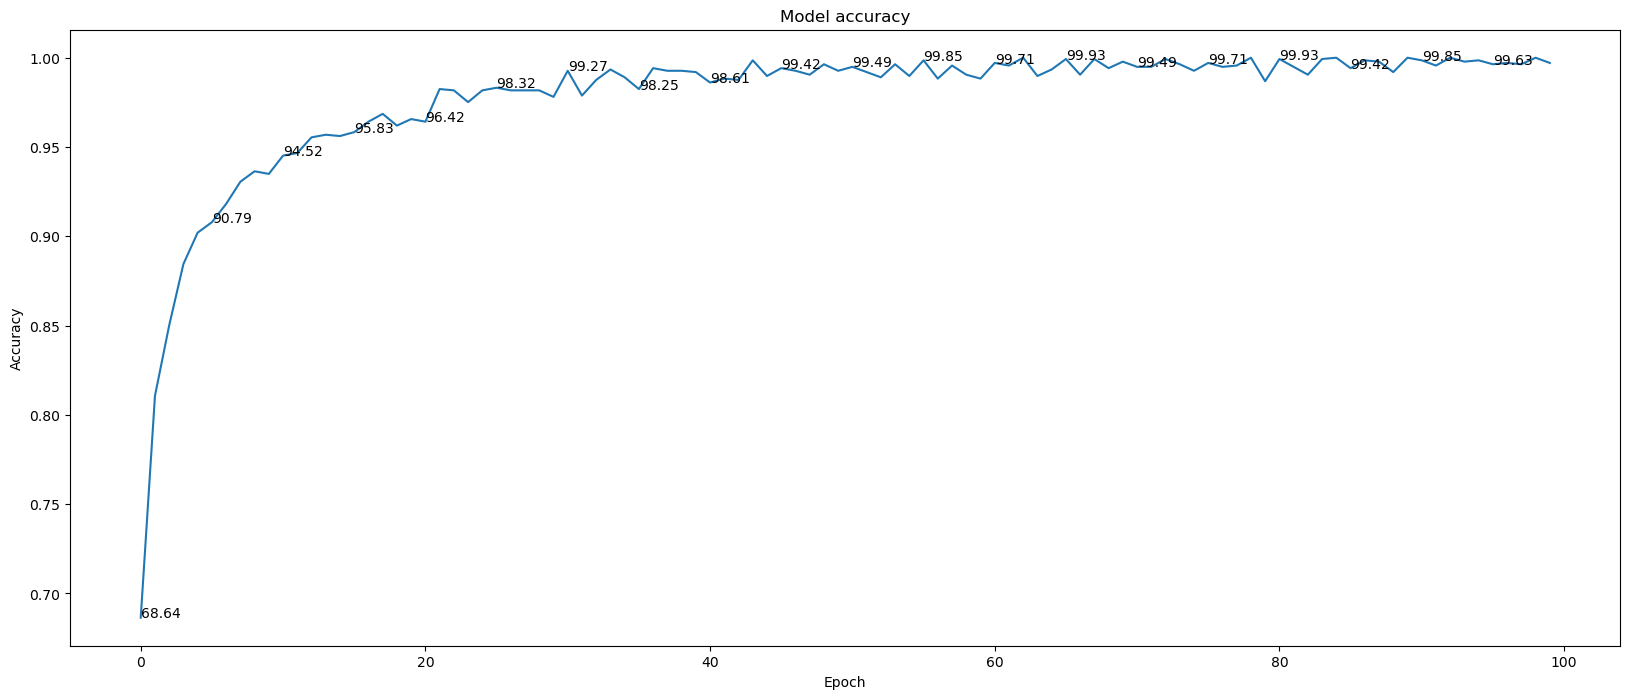

In [9]:
plt.figure(figsize=(20, 8))
plt.plot(history.history['accuracy'])

for i in range(epochs):
    if i%5 == 0:
        plt.annotate(np.round(history.history['accuracy'][i]*100,2),xy=(i,history.history['accuracy'][i]))

plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.show()

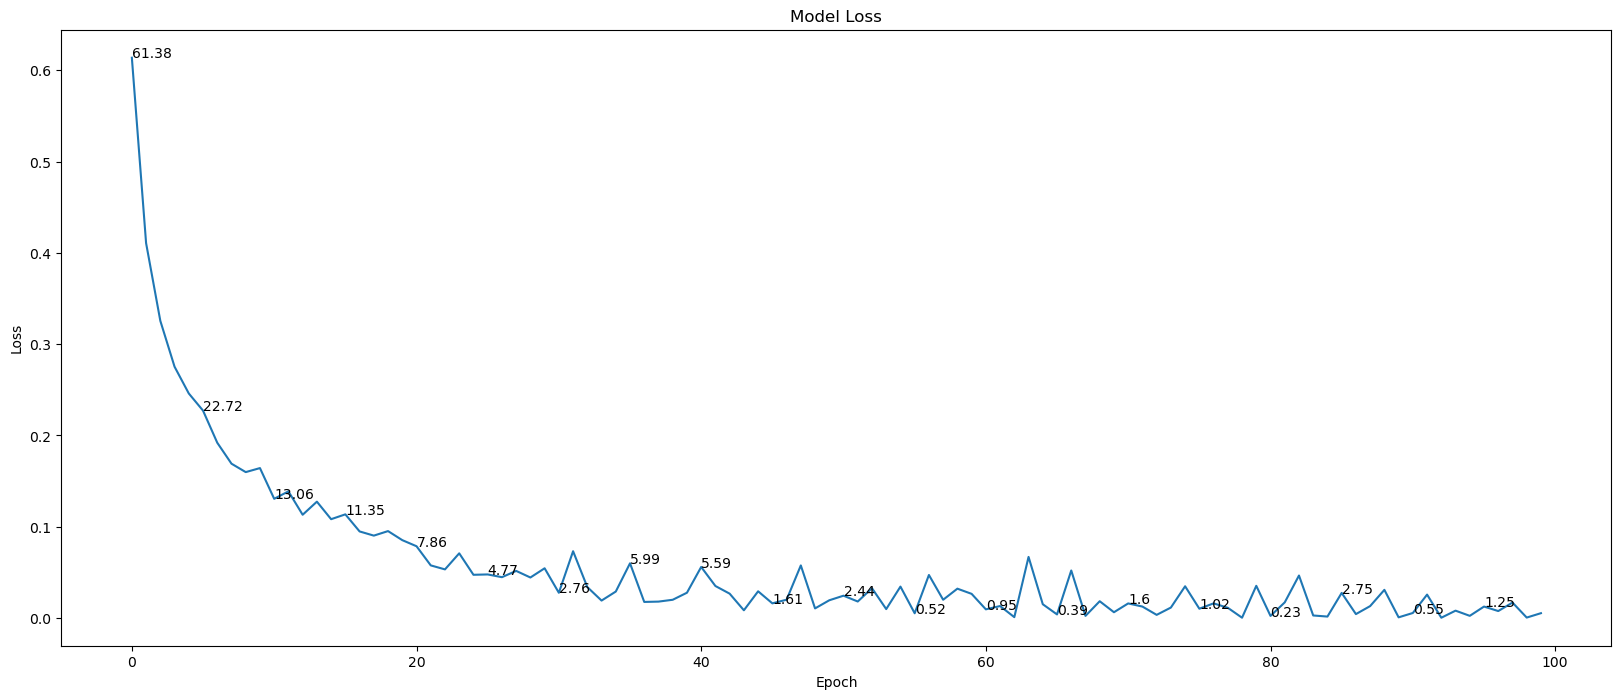

In [10]:
plt.figure(figsize=(20, 8))
plt.plot(history.history['loss'])

for i in range(epochs):
    if i%5 == 0:
        plt.annotate(np.round(history.history['loss'][i]*100,2),xy=(i,history.history['loss'][i]))

plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.show()